## [LAB-07] 추론통계

### 05-2_상관분석의 가정

### #01 준비작업

#### 1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *
from pandas import DataFrame

import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import linear_reset
from scipy.stats import pearsonr, spearmanr

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


#### 2. 데이터 가져오기

In [2]:
origin = load_data('language_math_scores')
origin.head()

📚 어느 학급의 언어영역과 수리영역 점수를 기록한 가상의 데이터 셋


,언어영역,수리영역
0,66,66
1,58,70
2,73,74
3,52,58
4,72,79


### #02 상관분석의 가정 확인

#### 1. 정규성

In [3]:
report = my_stats.test_assumptions(origin, columns=["언어영역", "수리영역"])
norm_x = bool(report.loc["언어영역", "result"])
norm_y = bool(report.loc["수리영역", "result"])
print(f"정규성 -> 언어영역: {norm_x}, 수리영역: {norm_y}")

정규성 -> 언어영역: True, 수리영역: True


#### 2. 선형성

- X가 증가할 때 Y도 증가하거나 감소하는 형태가 선형으로 분포해야 한다.
- 곡선형태로 분포할 경우 상관계수가 매우 낮거나 0의 상관을 보인다.
- 산점도 그래프를 통해 분석가가 직접 눈으로 보고 주관적으로 판단하는 것이 일반적이다.

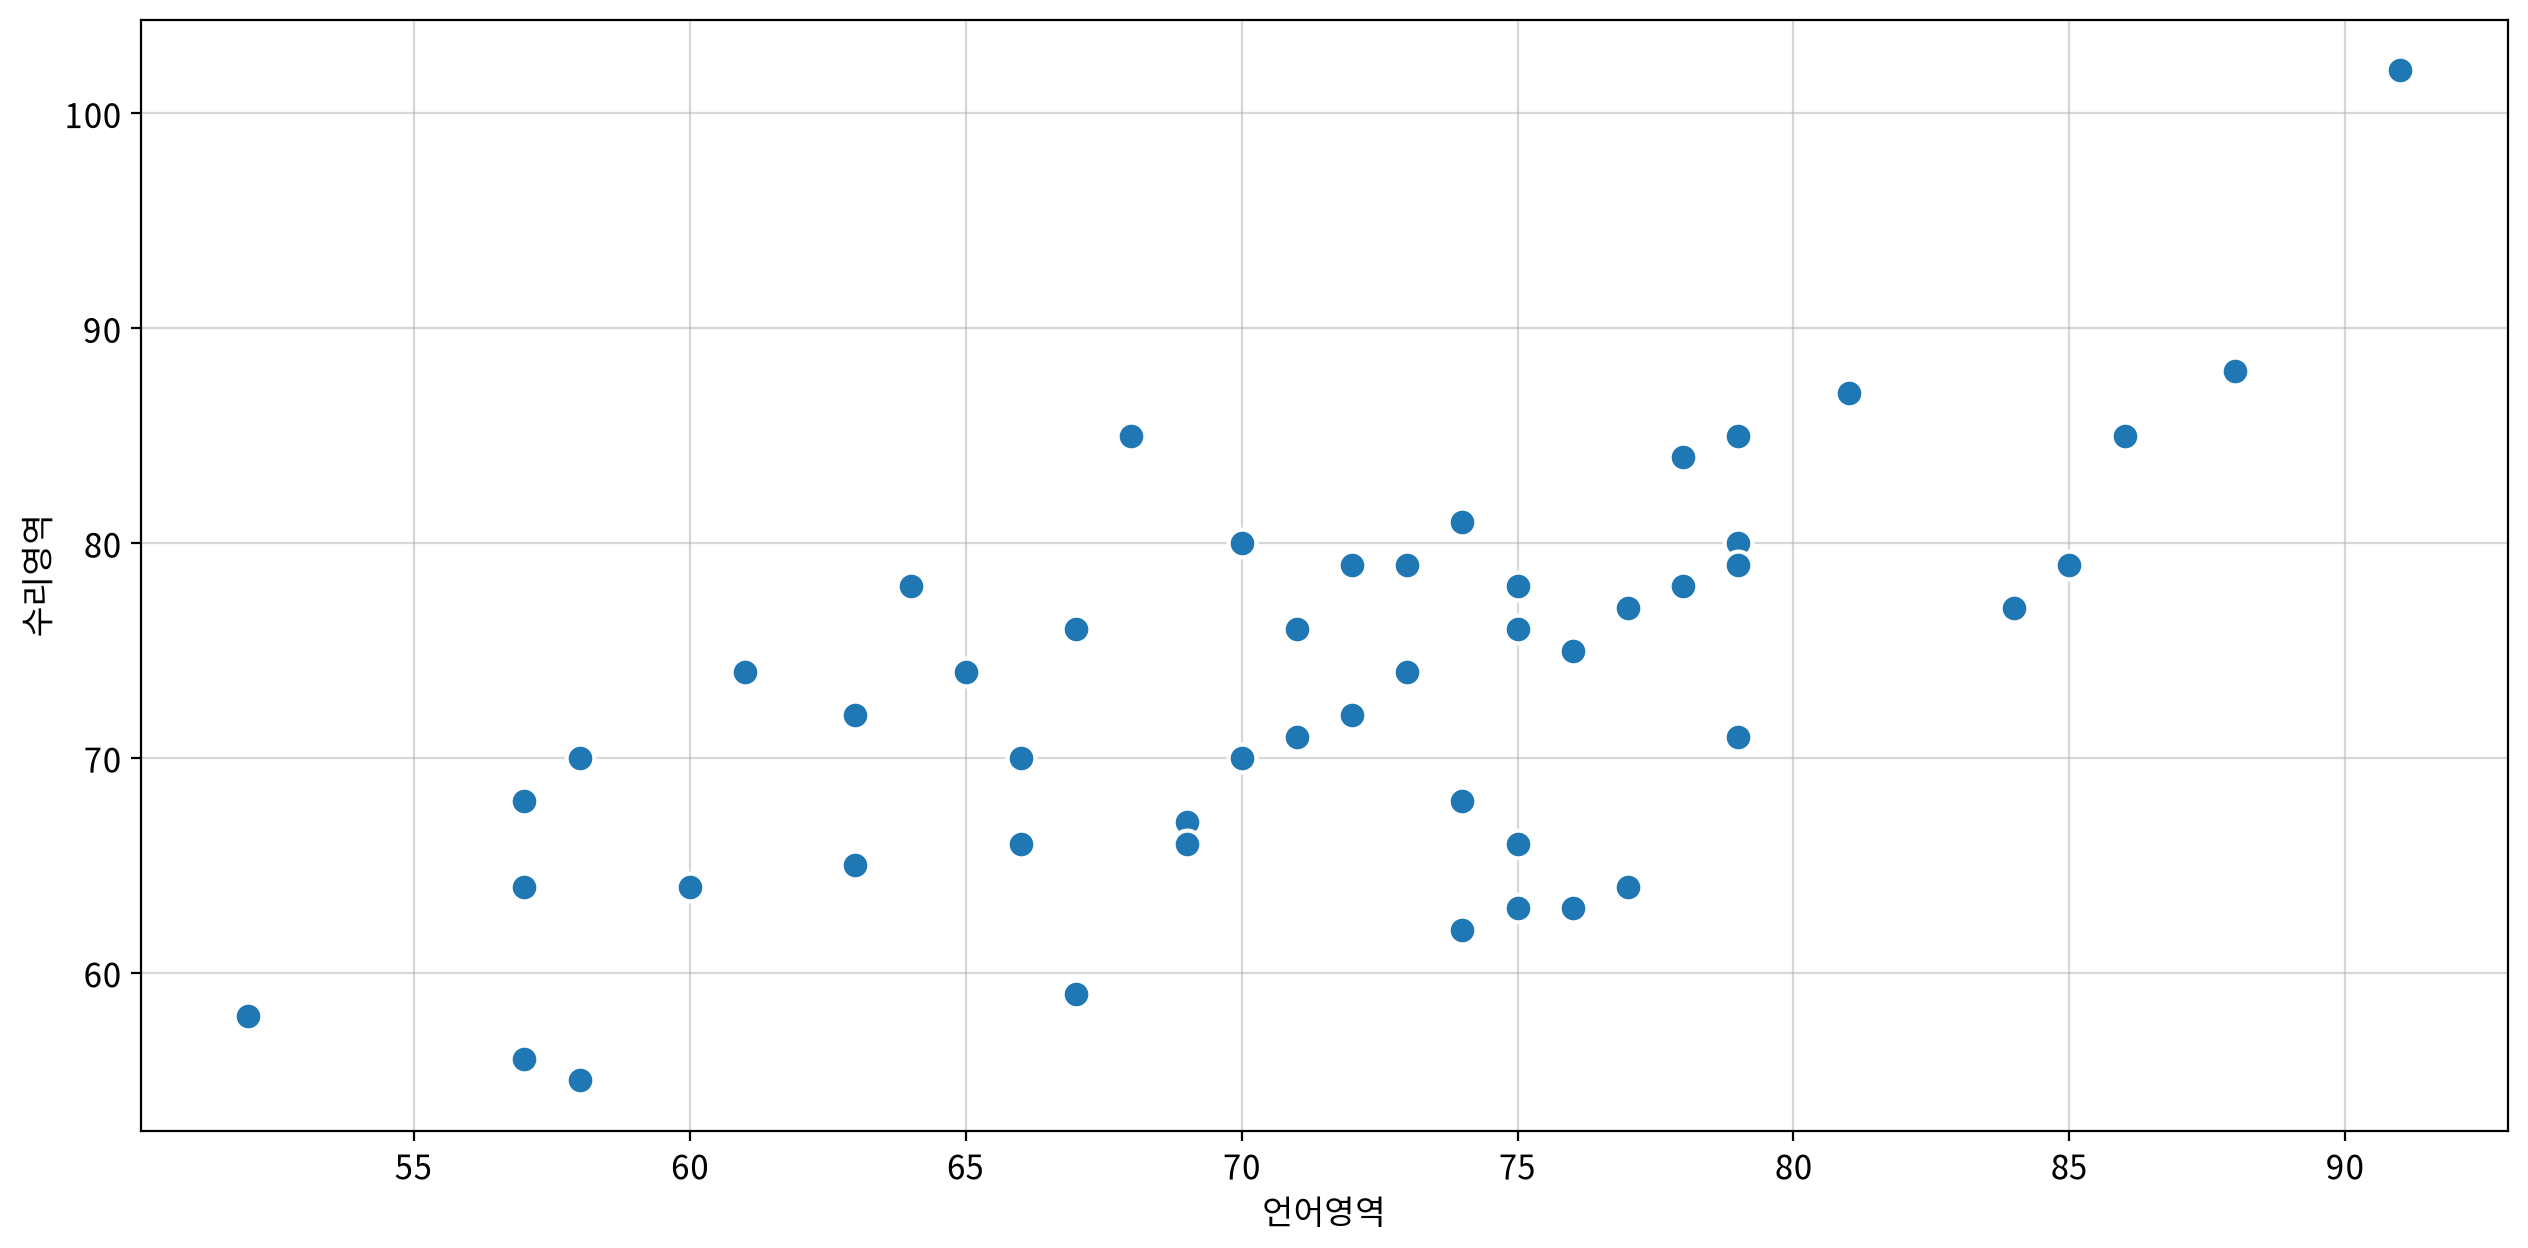

In [4]:
my_plot.scatterplot(origin, x='언어영역', y='수리영역')

> 인사이트
> - 언어영역 점수가 높을 수록 수리영역 점수도 함께 높아지는 경향이 있음
> - 두 변수는 대체로 직선적인 관계를 보임
> - 다만 점들이 넓게 퍼져 있어 관계가 아주 강하다고 보긴 어려움
> - 일부 벗어난 점도 보여서 해석할 때 같이 봐야 함

#### 3. 선형성의 통계적 검정 (Ramsey RESET Test)

RESET : Regression Equation Specification Error Test (회귀설정 오류 검정)
- 회귀 모델이 선형인지 검정하는 방법
    - 변수 간의 선형성을 직접적으로 검정하는 방법은 아니기 때문에 보조적인 방법으로 활용해야 함
- p >= 0.05 : 선형성 적합 (피어슨 상관계수 사용 가능)
- p < 0.05 : 선형성 위반 (스피어만 상관계수 사용 권장)

In [5]:
x = origin['언어영역']
y = origin['수리영역']

X = sm.add_constant(x)      # 상수항 추가 (선형회귀에서 자세히 다룸)
model = sm.OLS(y, X).fit()
reset = linear_reset(model, power=2, use_f=True)

print(f"Ramsey RESET Test : {reset.pvalue:.4f}")

Ramsey RESET Test : 0.1884


#### 4. 이상치 점검

In [6]:
results = {}

for col in ['언어영역', '수리영역']:
    # 특정 변수만 결측치를 제거하고 추출
    temp = origin[col].dropna()

    # 사분위수 기반 이상치 개수 계산
    q1 = temp.quantile(0.25)
    q3 = temp.quantile(0.75)
    iqr = q3 - q1
    out_iqr = int(np.sum((temp < q1 - 1.5 * iqr) | (temp > q3 + 1.5 * iqr)))

    results[col] = {
        # 왜도 (분포의 비대칭성)
        'skew': temp.skew(),
        # 사분위수(IQR) 기반 이상치 개수
        'outliers(IQR)': out_iqr,
    }

results_df = DataFrame(results).T
results_df

,skew,outliers(IQR)
언어영역,-0.103,0.000
수리영역,0.367,1.000


#### 5. 이상치에 따른 상관계수 변화 확인

In [7]:
# 두 변수를 함께 결측 제거한 원본 데이터
df_full = origin[["언어영역", "수리영역"]].dropna()

# IQR(사분위수) 울타리를 벗어나지 않은 행만 남겨 이상치 제거 데이터프레임을 별도로 생성
df_trim = df_full.copy()

for col in ['언어영역', '수리영역']:
    # 울타리는 항상 원본(df_full) 기준으로 계산
    q1 = df_full[col].quantile(0.25)
    q3 = df_full[col].quantile(0.75)
    iqr = q3 - q1
    df_trim = df_trim[(df_trim[col] >= q1 - 1.5 * iqr) &
                      (df_trim[col] <= q3 + 1.5 * iqr)]

# 원본과 이상치 제거 데이터에 대한 피어슨 상관계수 계산
r_full = pearsonr(df_full["언어영역"], df_full["수리영역"])[0]
r_trim = pearsonr(df_trim["언어영역"], df_trim["수리영역"])[0]

print(f"피어슨 r (전체)      : {r_full:.3f}  (n={len(df_full)})")
print(f"피어슨 r (이상치 제외): {r_trim:.3f}  (n={len(df_trim)})")
print(f"변화량              : {abs(r_full - r_trim):.3f}")

피어슨 r (전체)      : 0.671  (n=50)
피어슨 r (이상치 제외): 0.622  (n=49)
변화량              : 0.049


#### 6. 이상치 영향 판정

In [8]:
# 왜도가 크다 (|skew| > 1)
skew_flag = bool((results_df['skew'].abs() > 1).any())

# 이상치가 상관계수를 크게 바꾼다
influential_flag = bool(abs(r_full - r_trim) >= 0.1)

print(f"이상치 영향: {influential_flag or skew_flag}")

이상치 영향: False


> - 상관분석의 가정(선형성, 이상치 영향)을 확인한 결과<br>선형성을 만족하고 이상치에 영향을 받지 않으므로 Pearson 상관계수를 채택한다.

### #03 모듈화 기능 확인

#### 1. 가정 확인 -> 상관 분석 자동화

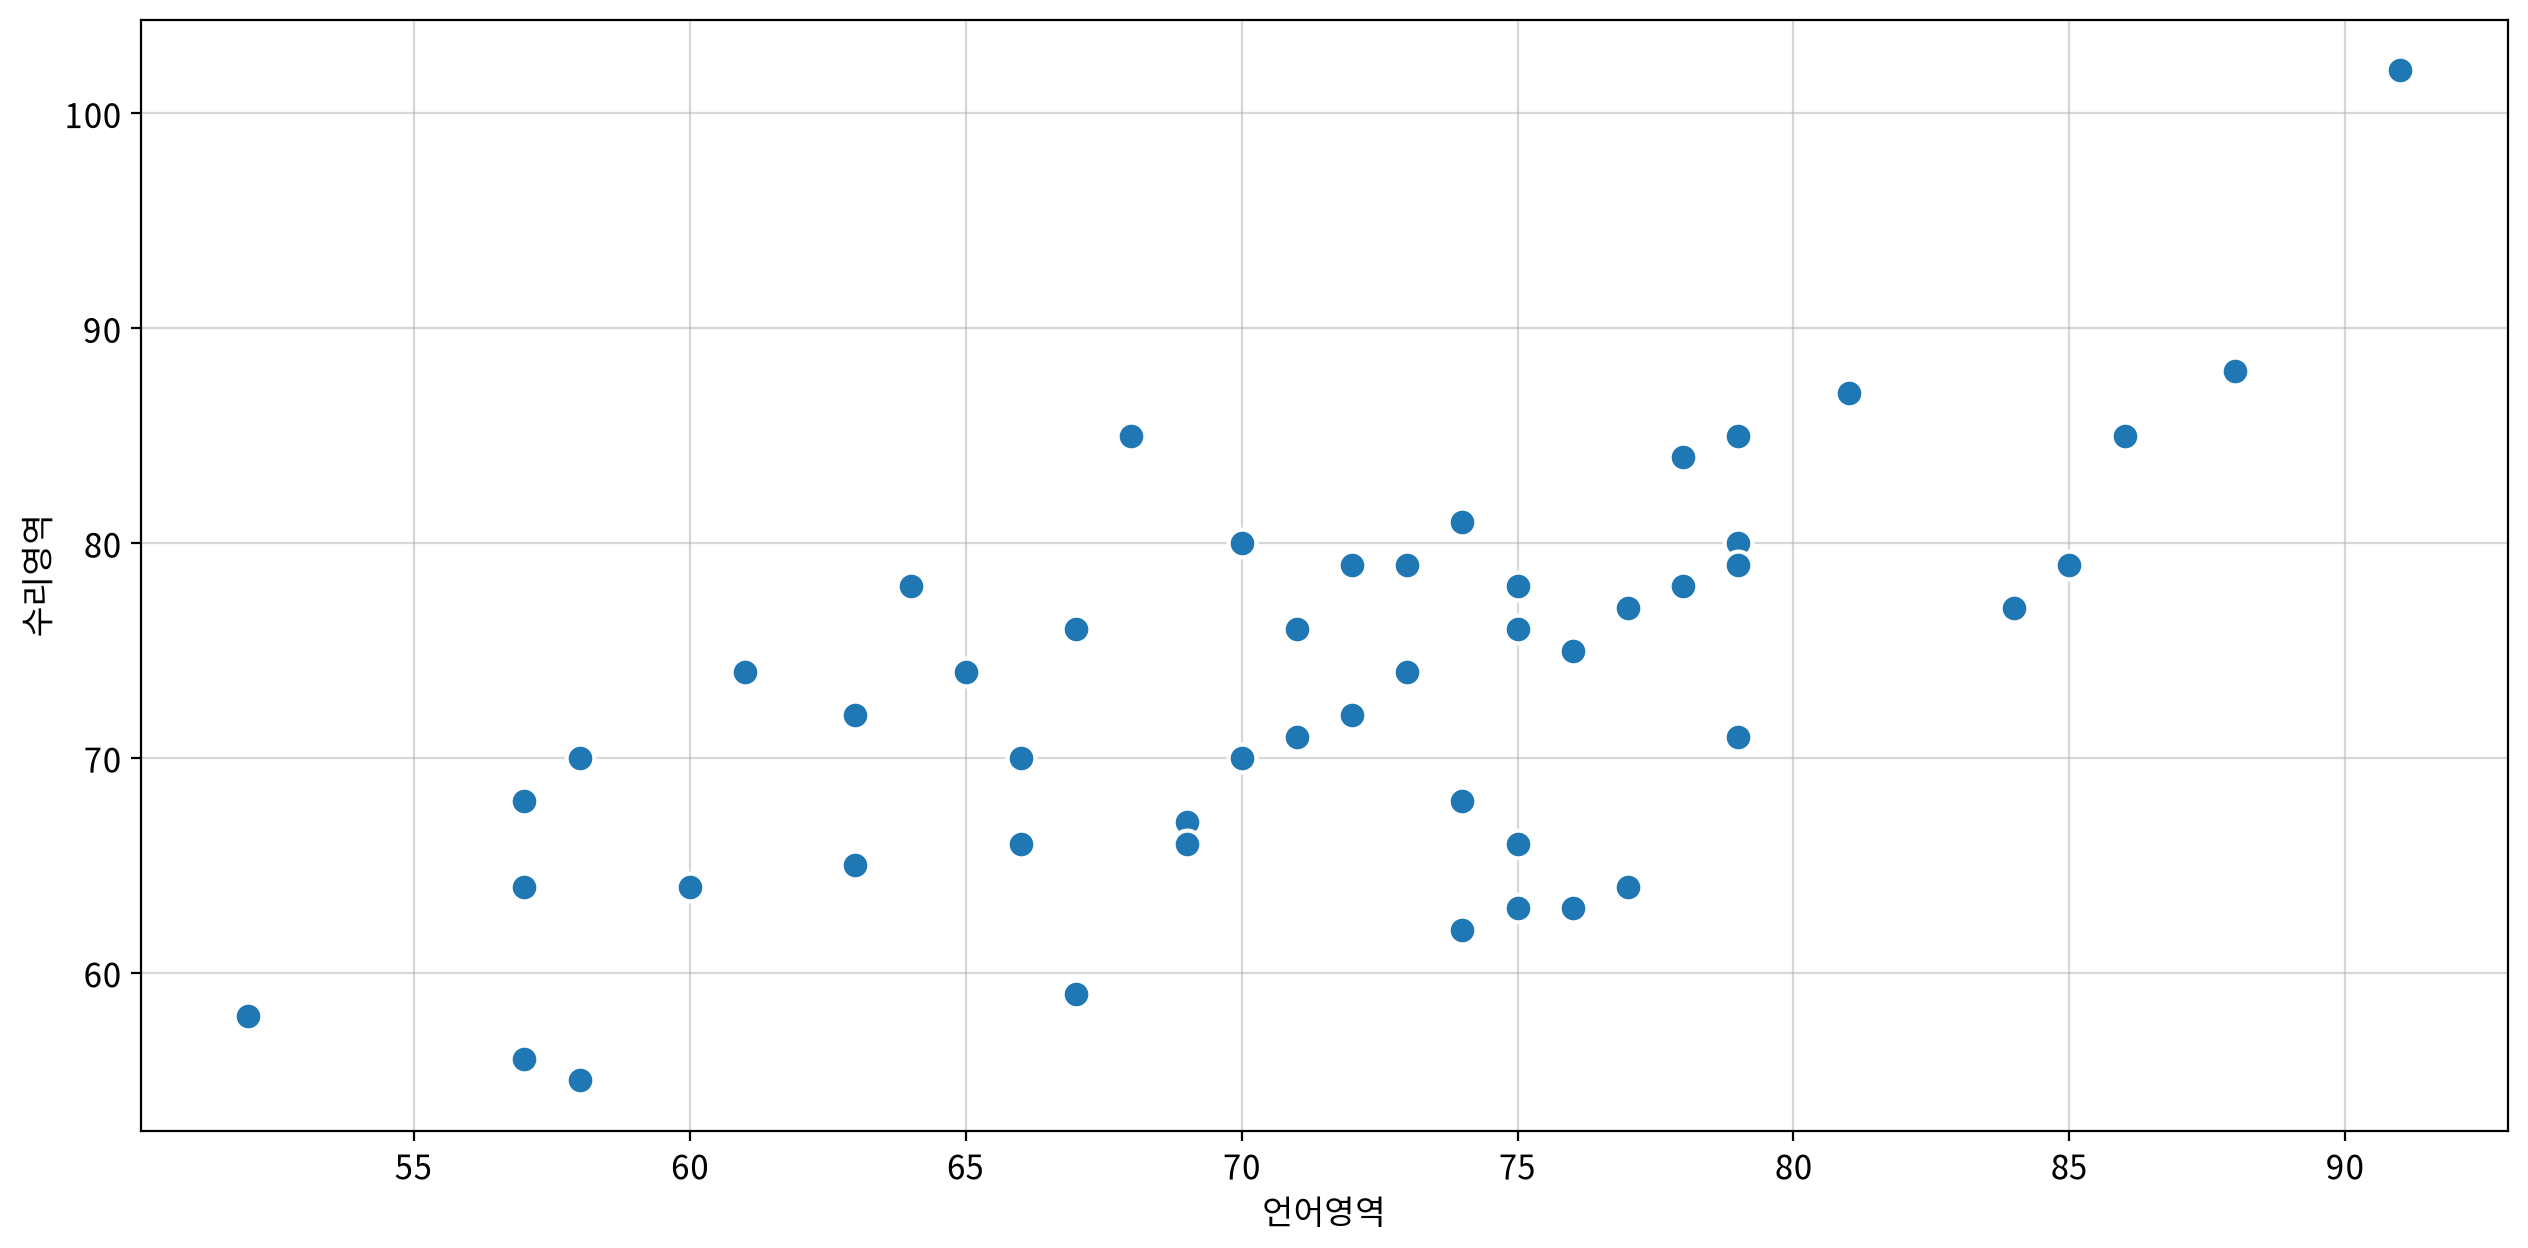

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
언어영역,수리영역,Pearson,0.671,0.000,Moderate,True,True,True,True,False,False


In [9]:
my_stats.correlation(origin, "언어영역", "수리영역")

> - **중간 정도의 양의 상관관계** -- 피어슨 계수 0.671(strength: Moderate). 언어영역 점수가 높을 수록 수리영역 점수도 함께 높아지는 경향이 있음.
> - **통계적으로 유의함** -- p-value ≈ 0.000(<0.05), significant=True. 이 상관관계는 우연으로 보기 어려움.
> - **피어슨 계수를 쓰는 것이 타당** -- 정규성(언어, 수리 모두 True), 선형성(True)을 충족하고, 영향점(influential_outlier=False), 큰 왜도(high_skew=False)도 없어 스피어만이 아닌 피어슨이 적절한 상황.
> - **다만 '강한' 관계는 아님** -- Moderate 수준이라 점들이 어느 정도 퍼져있음.<br>한 영역 점수만으로 다른 영역 점수를 단정적으로 예측하기는 어려움.

---

## 연습문제

### 문제1

- baseball 데이터셋은 야구팀의 홈런수와 타율에 관한 자료이다.
- 홈런수와 평균타율이 상관관계가 있는지 그 관련성을 유의수준 `5%`에서 분석하라.

In [11]:
df1 = load_data('baseball')
df1.head()

📚 야구팀의 홈런수와 타율에 관한 자료 (출처: 방송통신대학교 통계학 개론)


,홈런수,평균타율
0,174,0.277
1,163,0.276
2,161,0.272
3,230,0.272
4,214,0.269


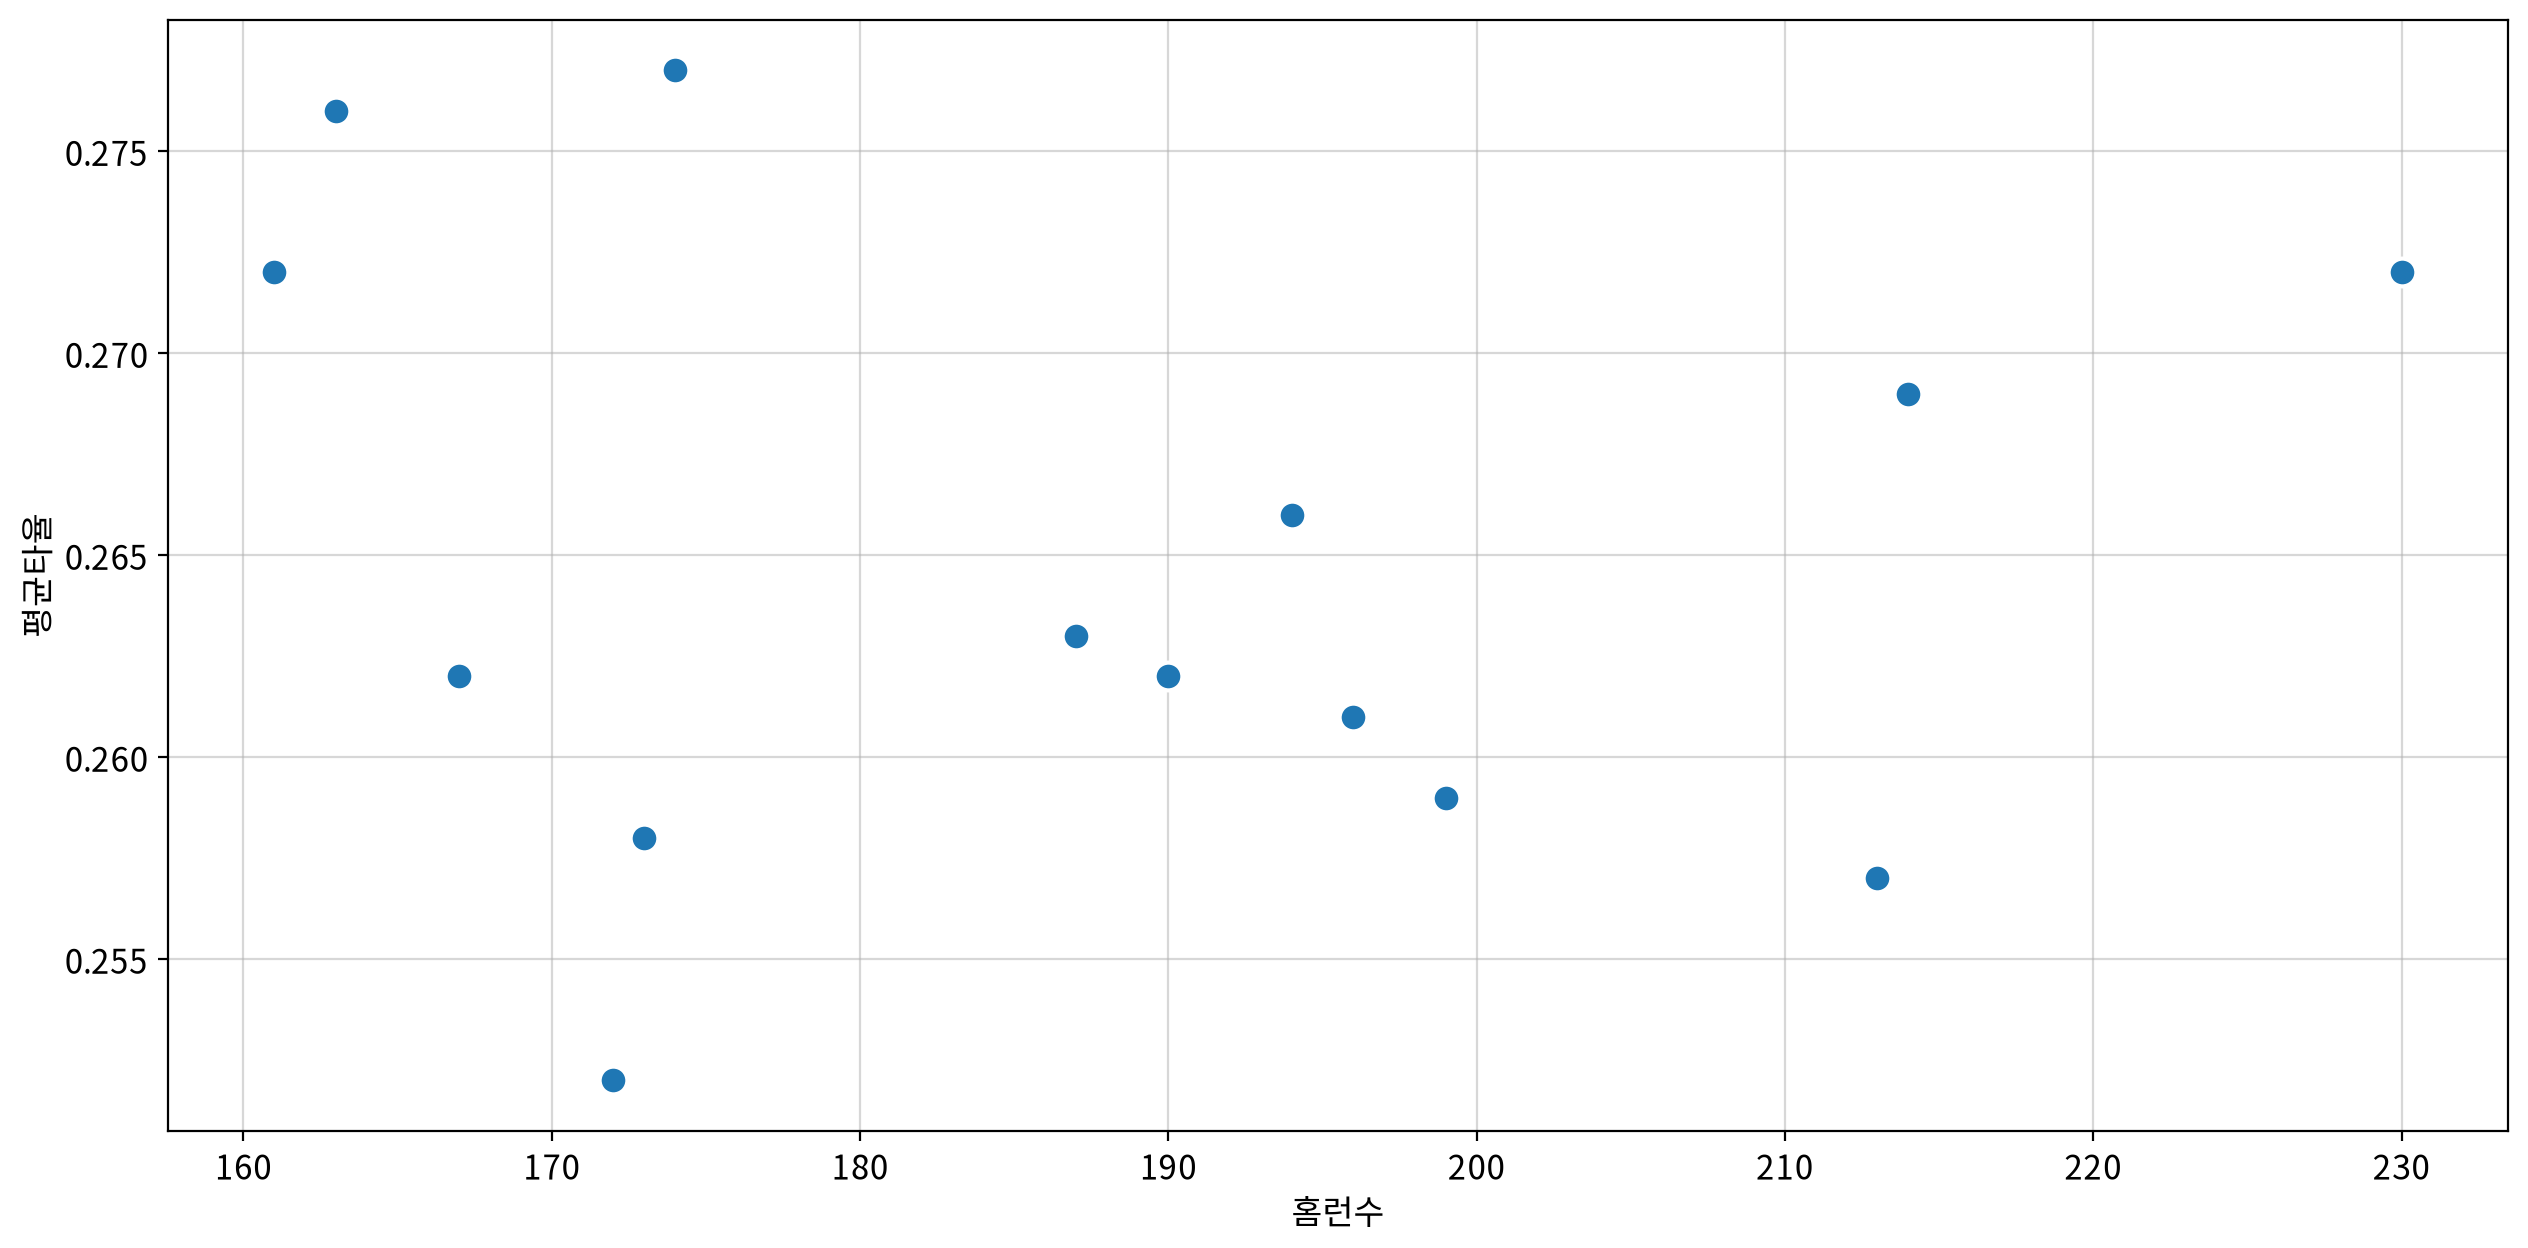

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
홈런수,평균타율,Pearson,-0.075,0.800,Weak,False,True,True,True,False,False


In [12]:
my_stats.correlation(df1, "홈런수", "평균타율")

홈런수와 평균타율이 상관관계는 유의수준 5%에서 통계적으로 유의하지 않다. 즉, 홈런수와 평균타율은 상관관계가 없다고 볼 수 있다.

### 문제2

- product 데이터셋은 어떤 원료의 품질특성(x)과 이 원료를 사용하여 만든 제품의 특성(y)에 관한 조사를 한 결과이다.
- 이들 간 상관관계를 구하고 상관 유무 검정을 유의수준 `5%`에서 실시하라.


In [13]:
df2 = load_data('product')
df2.head()

📚 어떤 원료의 품질특성(x)과 이 원료를 사용하여 만든 제품의 특성(y)에 관한 조사결과 (출처: 방송통신대학교 통계학 개론)


,x,y
0,36,29
1,40,32
2,34,29
3,44,40
4,33,31


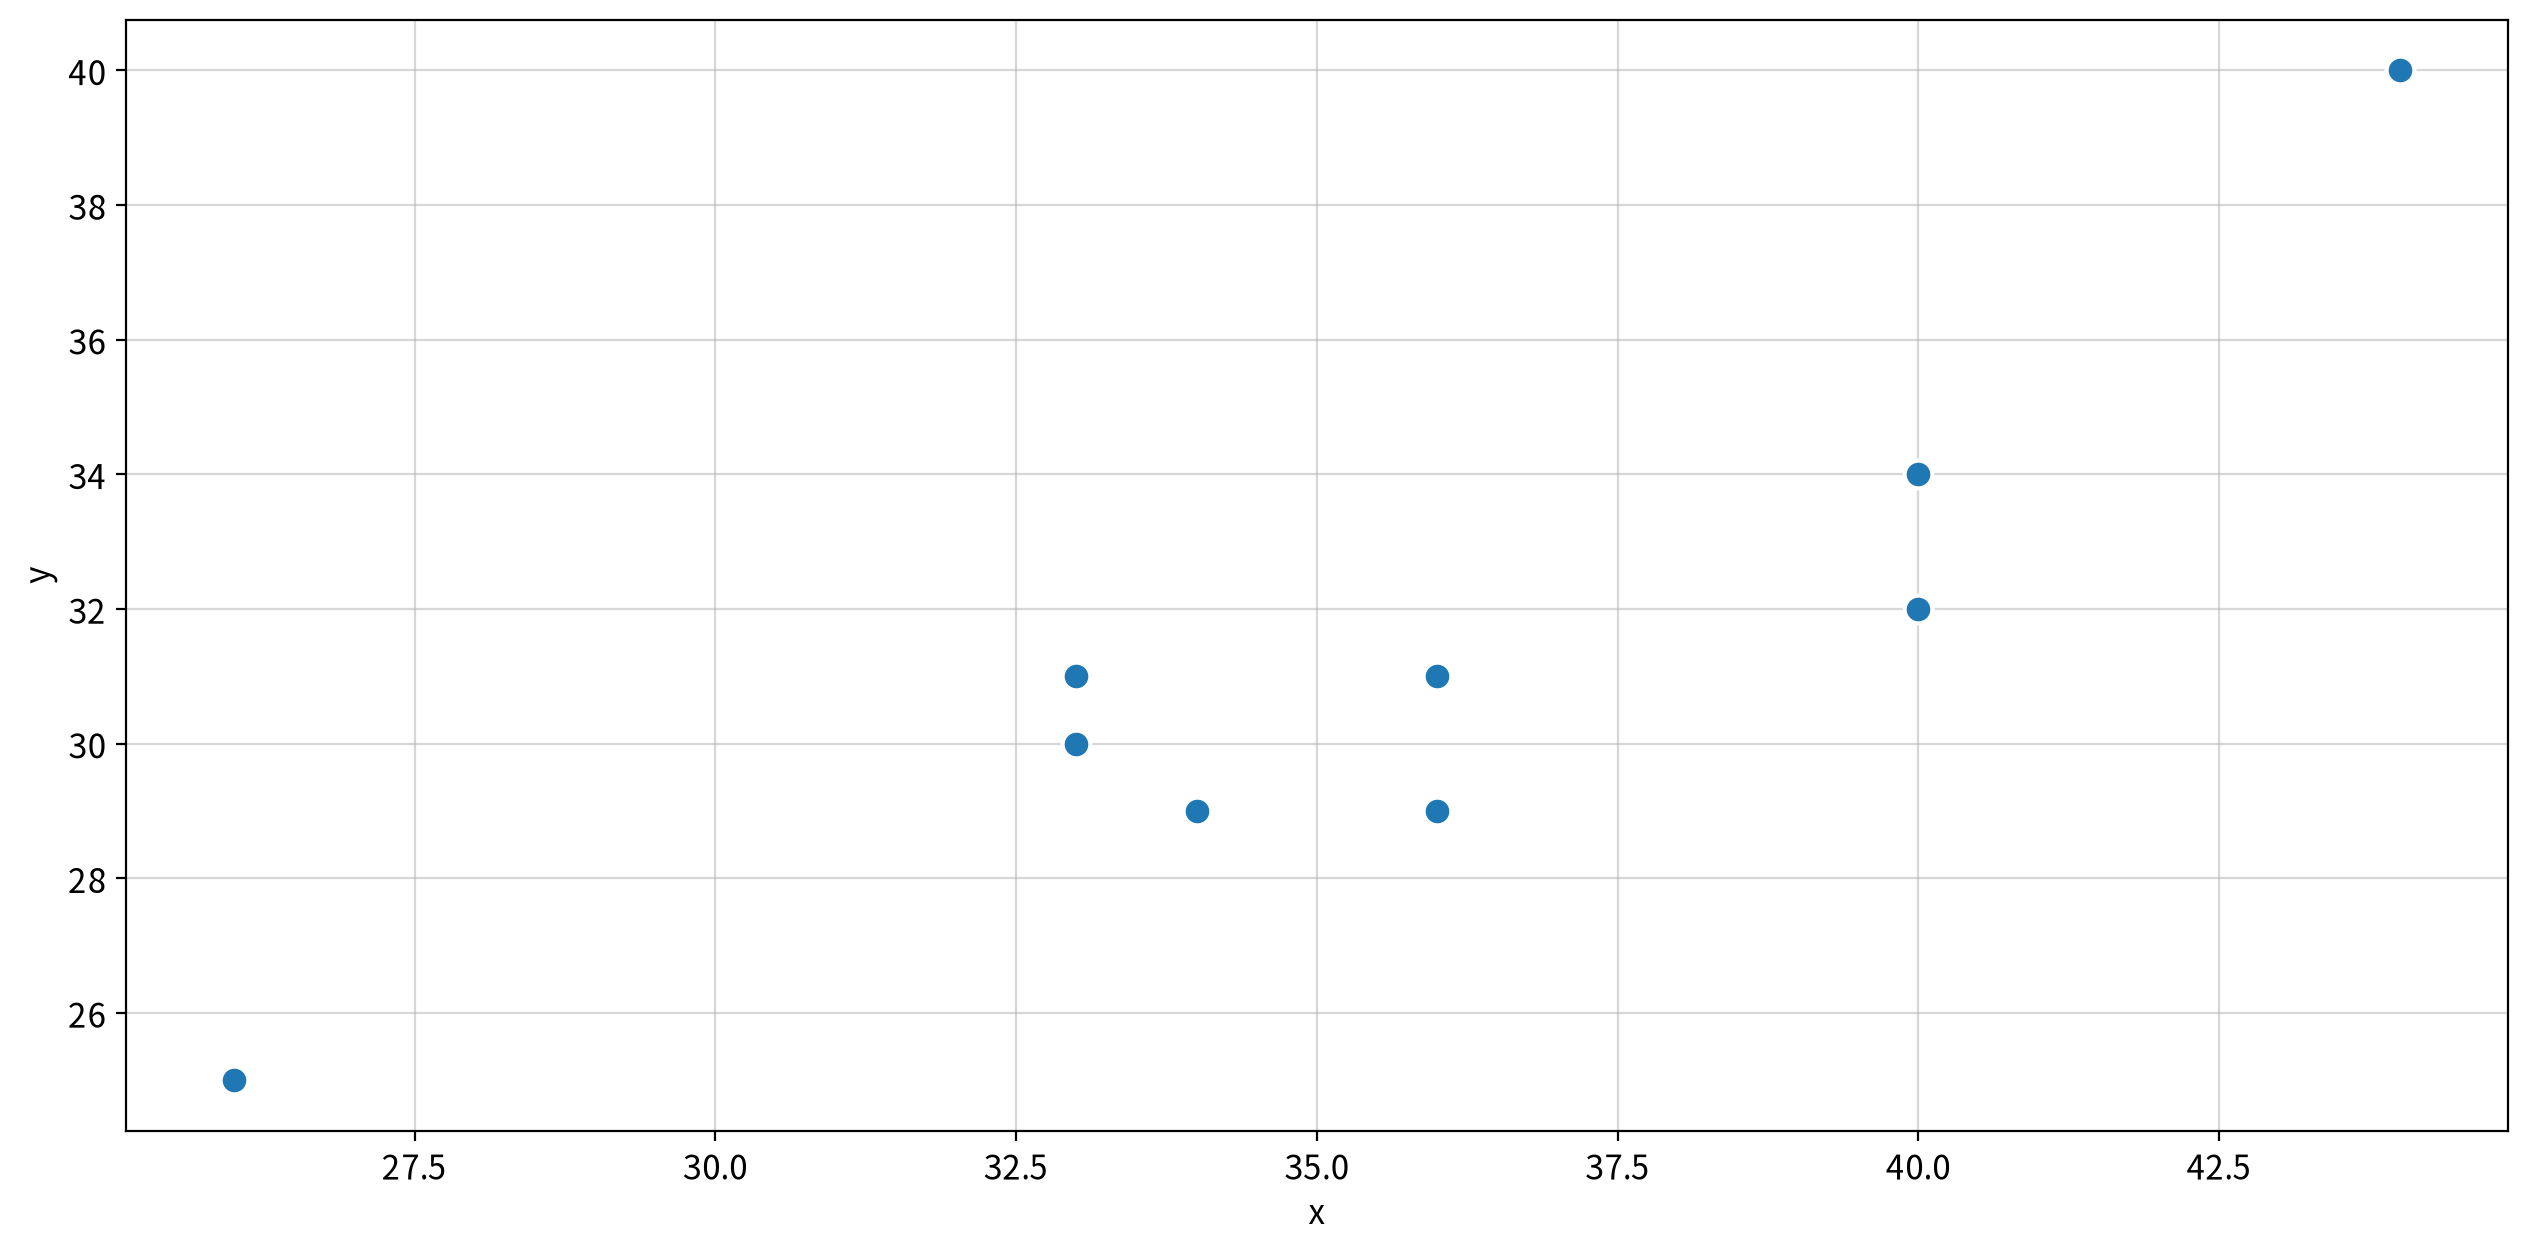

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
x,y,Spearman,0.737,0.015,Strong,True,True,False,True,False,True


In [15]:
my_stats.correlation(df2, "x", "y")

- **강한 양의 상관관계** -- 스피어만 계수 0.737(strength: Strong). 원료의 품질특성이 높을 수록 제품의 특성도 함께 높아지는 경향이 있음.
- **통계적으로 유의함** -- p-value ≈ 0.015(<0.05), significant=True. 이 상관관계는 우연으로 보기 어려움.
- **스피어만 계수를 쓰는 것이 타당** -- 정규성 위반(normality_y=False), 큰 왜도(high_skew=True)로 인해 스피어만이 적절한 상황.

### 문제3

- study_time 은 학생들에 대한 공부 시간과 성적 데이터이다. 분석하라.

In [16]:
df3 = load_data('study_time')
df3.head()

📚 학생들에 대한 공부 시간과 성적 데이터 (출처: 방송통신대학교 통계학 개론)


,공부시간,성적
0,2,65
1,4,85
2,3,75
3,5,90
4,6,95


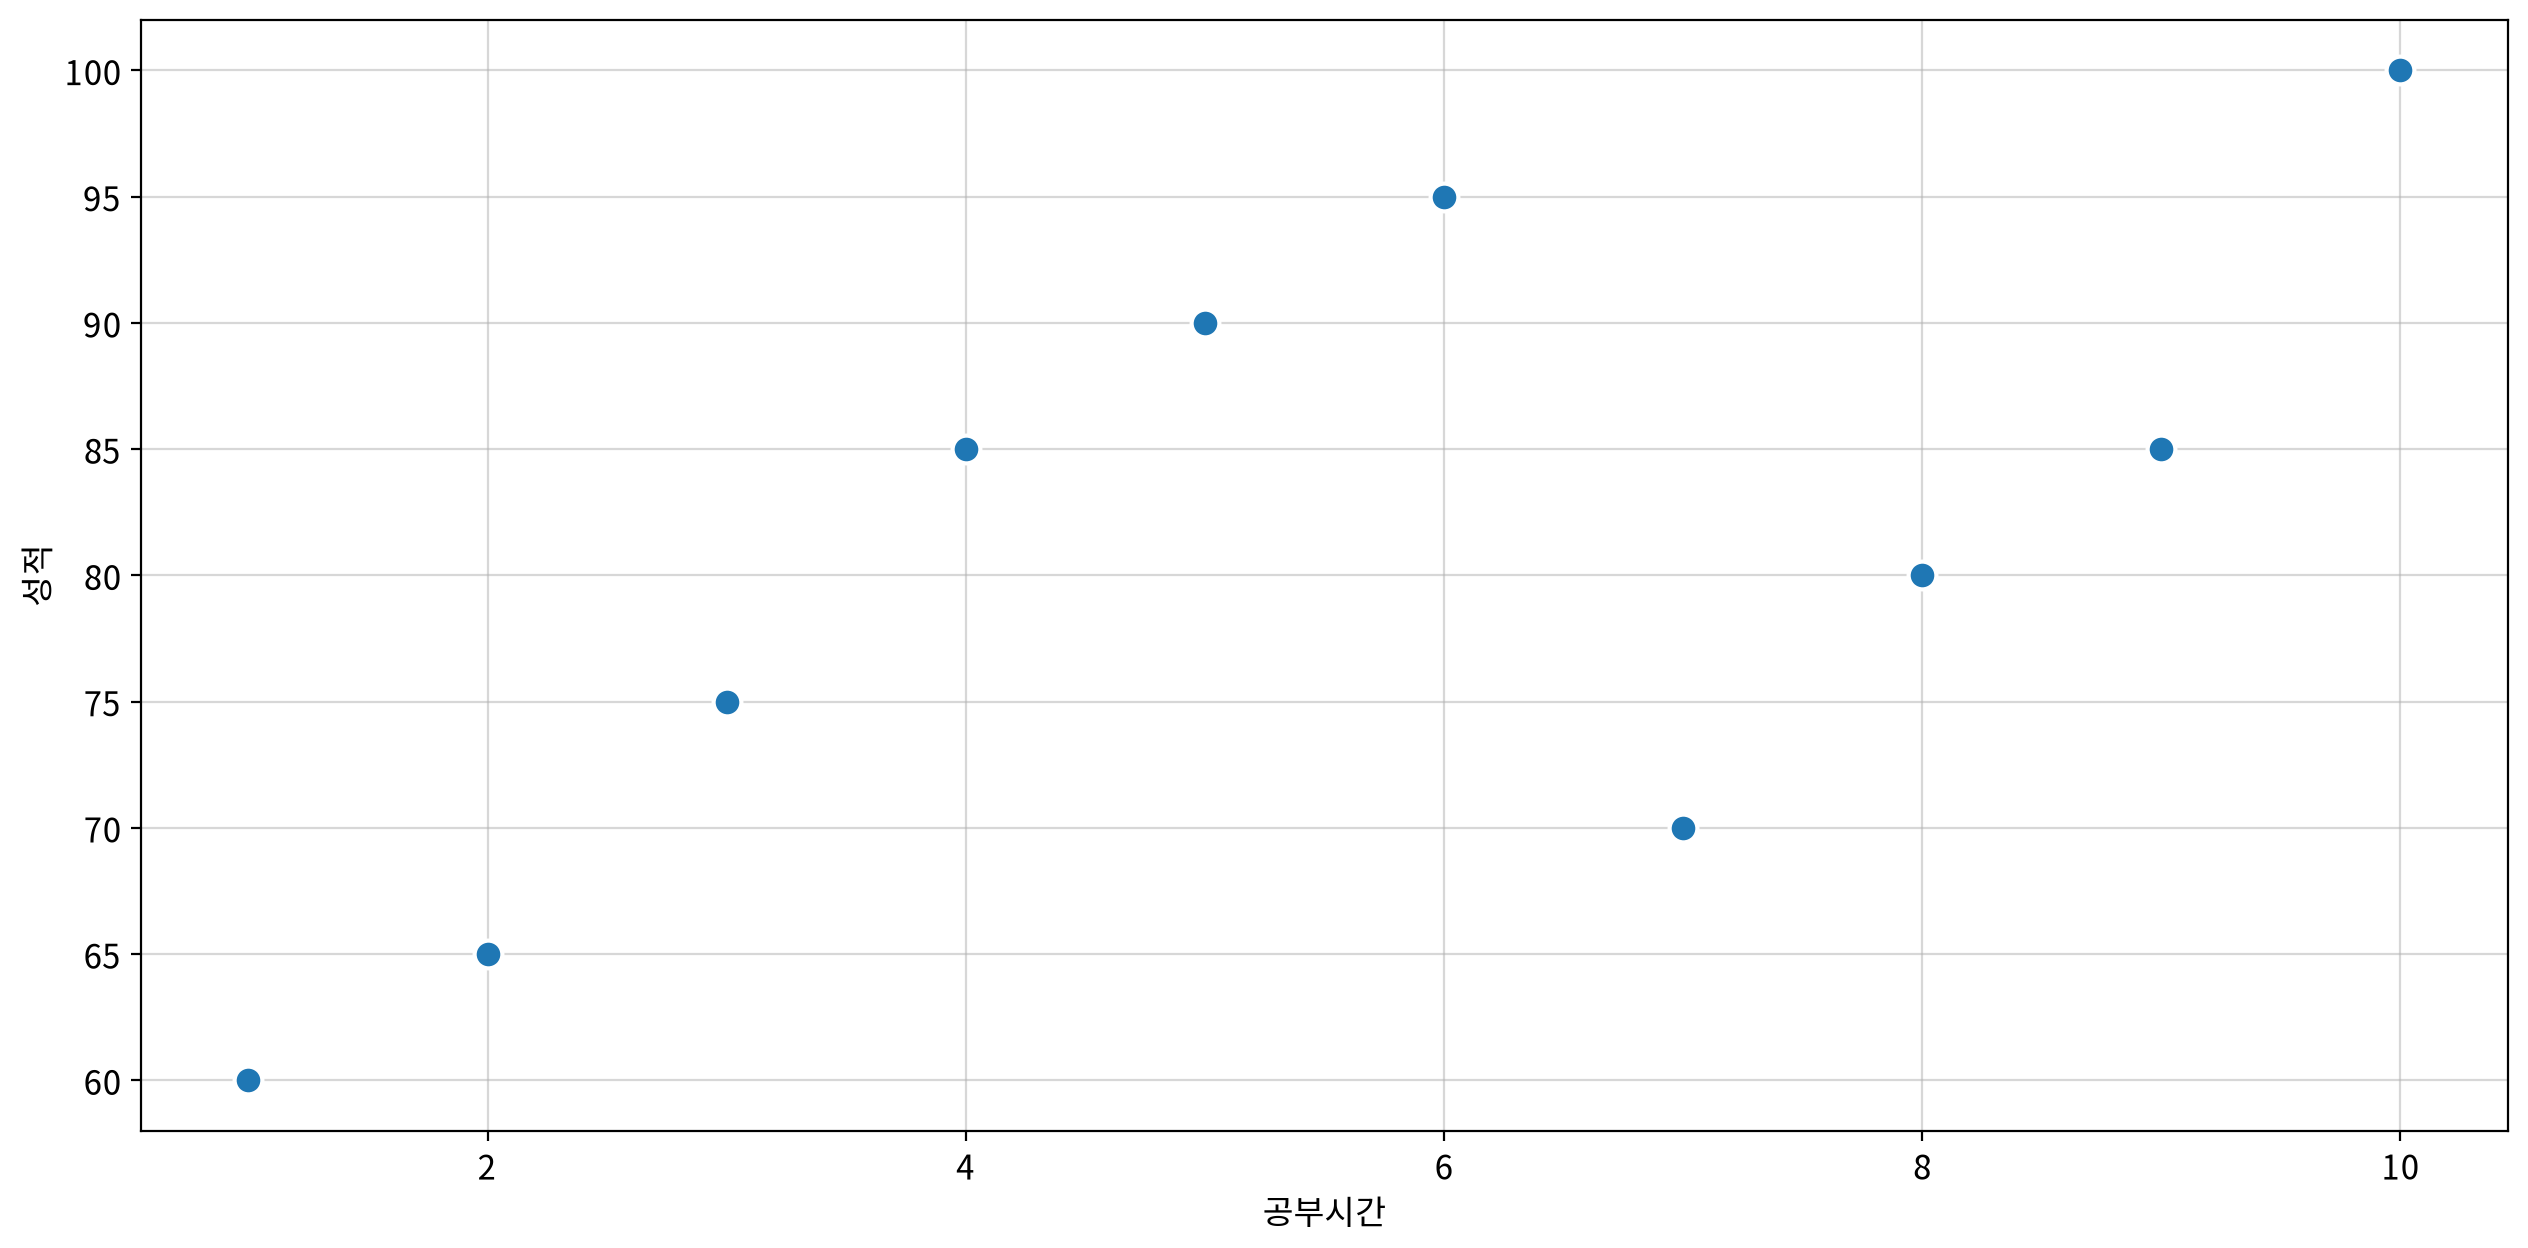

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
공부시간,성적,Pearson,0.684,0.029,Moderate,True,True,True,True,False,False


In [17]:
my_stats.correlation(df3, "공부시간", "성적")

- **중간 정도의 양의 상관관계** -- 피어슨 계수 0.684(strength: Moderate). 공부시간이 길 수록 성적도 함께 높아지는 경향이 있음.
- **통계적으로 유의함** -- p-value ≈ 0.029(<0.05), significant=True. 이 상관관계는 우연으로 보기 어려움.
- **피어슨 계수를 쓰는 것이 타당** -- 정규성(언어, 수리 모두 True), 선형성(True)을 충족하고, 영향점(influential_outlier=False), 큰 왜도(high_skew=False)도 없어 스피어만이 아닌 피어슨이 적절한 상황.
- **다만 '강한' 관계는 아님** -- Moderate 수준이라 점들이 어느 정도 퍼져있음.<br>한 영역 공부시간만으로 다른 영역 성적을 단정적으로 예측하기는 어려움.